100%|██████████| 170M/170M [11:15<00:00, 252kB/s]


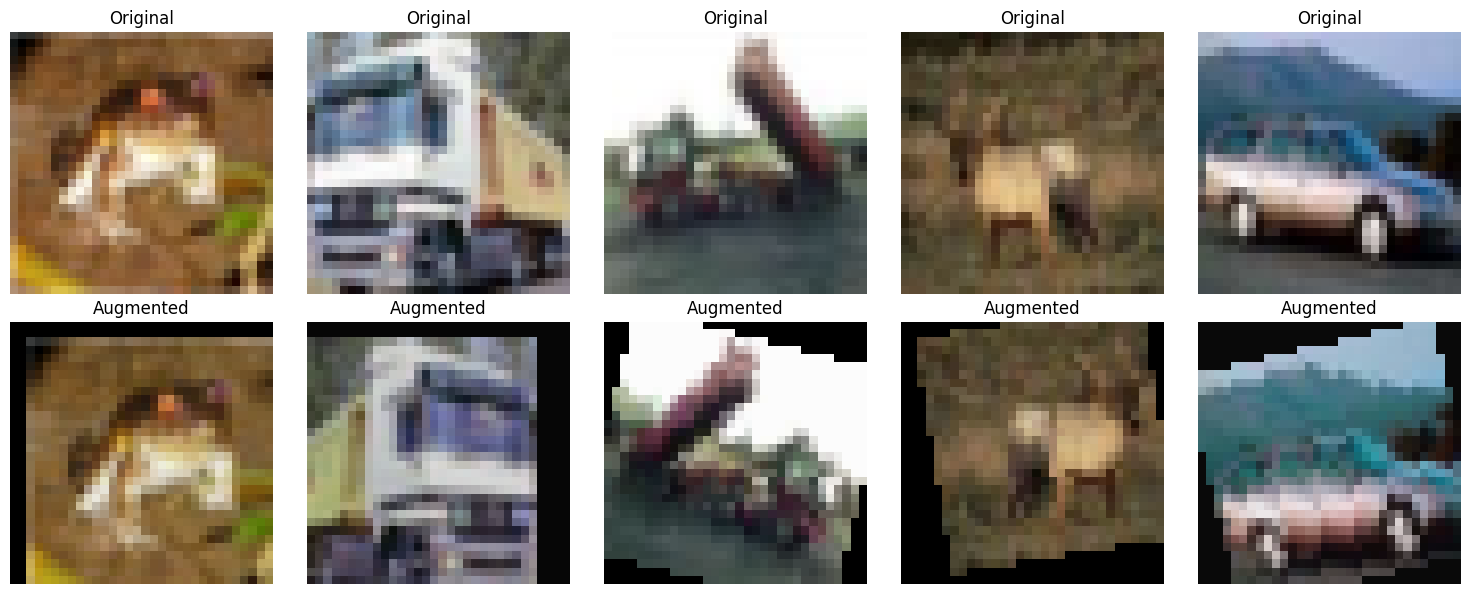

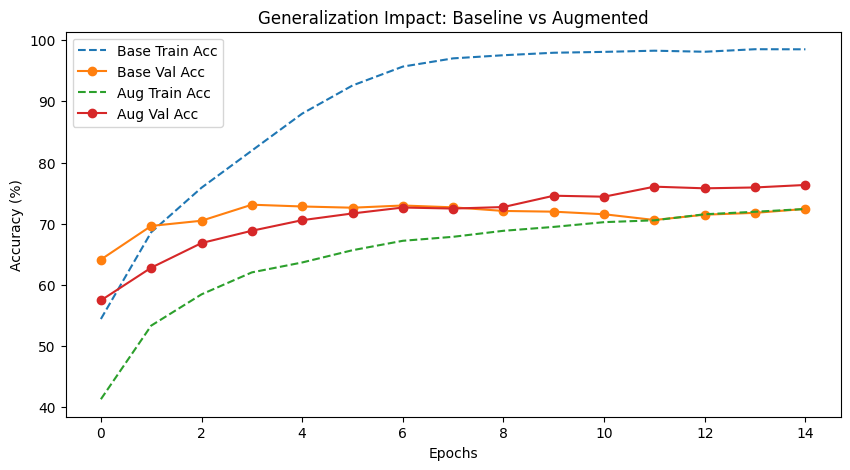

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

augmented_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset_base = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=baseline_transform)
test_dataset_base = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=baseline_transform)

train_dataset_aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=augmented_transform)
test_dataset_aug = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=baseline_transform)

train_loader_base = torch.utils.data.DataLoader(train_dataset_base, batch_size=64, shuffle=True)
test_loader_base = torch.utils.data.DataLoader(test_dataset_base, batch_size=64, shuffle=False)

train_loader_aug = torch.utils.data.DataLoader(train_dataset_aug, batch_size=64, shuffle=True)
test_loader_aug = torch.utils.data.DataLoader(test_dataset_aug, batch_size=64, shuffle=False)

def show_augmented_samples(dataset_base, dataset_aug):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))

    for i in range(5):
        img_base, _ = dataset_base[i]
        img_base = img_base / 2 + 0.5
        npimg_base = img_base.numpy()
        axes[0, i].imshow(np.transpose(npimg_base, (1, 2, 0)))
        axes[0, i].axis('off')
        axes[0, i].set_title("Original")

        img_aug, _ = dataset_aug[i]
        img_aug = img_aug / 2 + 0.5
        npimg_aug = img_aug.numpy()
        axes[1, i].imshow(np.transpose(npimg_aug, (1, 2, 0)))
        axes[1, i].axis('off')
        axes[1, i].set_title("Augmented")

    plt.tight_layout()
    plt.show()

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 8 * 8, 512)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

def train_model(model, train_loader, test_loader, epochs=15):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        correct, total = 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        history['train_acc'].append(100. * correct / total)

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        history['val_acc'].append(100. * correct / total)

    return history

if __name__ == "__main__":
    show_augmented_samples(train_dataset_base, train_dataset_aug)

    model_base = SimpleCNN()
    history_base = train_model(model_base, train_loader_base, test_loader_base, epochs=15)

    model_aug = SimpleCNN()
    history_aug = train_model(model_aug, train_loader_aug, test_loader_aug, epochs=15)

    plt.figure(figsize=(10, 5))
    plt.plot(history_base['train_acc'], label='Base Train Acc', linestyle='--')
    plt.plot(history_base['val_acc'], label='Base Val Acc', marker='o')
    plt.plot(history_aug['train_acc'], label='Aug Train Acc', linestyle='--')
    plt.plot(history_aug['val_acc'], label='Aug Val Acc', marker='o')
    plt.title('Generalization Impact: Baseline vs Augmented')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.show()